`ngs` env

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from Bio.Seq import Seq
from Bio import motifs

In [25]:
import logomaker

In [15]:
library_path = '../ScreenProcessing/library_tables/CRISPRi_v2_human_librarytable.txt'

library = pd.read_csv(
    library_path,
    sep='\t', 
    header=0, 
    index_col=0
)

In [16]:
library.sequence.str.len().unique()

array([20])

# 

In [20]:
def draw_logo(m,l,ax):
    df = pd.DataFrame(m.counts,dtype=int)

    for n in ['A','T','C','G']: 
        df[n] = df[n] / l

    crp_logo = logomaker.Logo(df,
                             fade_probabilities=True,
                              shade_below=.5,
                              fade_below=.5,
                              ax=ax
                              # font_name='Arial Rounded MT Bold'
                             )
    return crp_logo

___

In [26]:
m = motifs.create(library.sequence.to_list()); l = len(library.sequence.to_list())

in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...


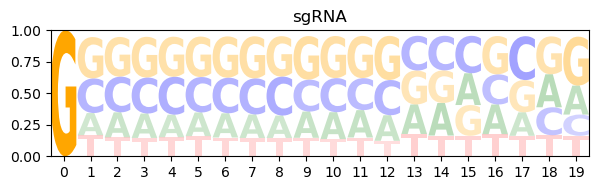

In [33]:
fig, ax = plt.subplots(1, 1,figsize=(6,2), sharey=True, tight_layout=True)

_ = draw_logo(m, l, ax); ax.set_title('sgRNA')
ax.xaxis.set_major_locator(ticker.MultipleLocator())

# plt.savefig('motif_logo.pdf')
plt.show()